# CNN

2025-07-26 11:21:28.498090: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753528888.851394      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753528888.957007      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
I0000 00:00:1753530593.665546      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1753530593.666226      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability:

Epoch 1/10


I0000 00:00:1753530600.335018     101 service.cc:148] XLA service 0x794d90006f80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1753530600.336370     101 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1753530600.336391     101 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1753530600.712890     101 cuda_dnn.cc:529] Loaded cuDNN version 90300


  18/2434 ━━━━━━━━━━━━━━━━━━━━ 23s 10ms/step - accuracy: 0.5106 - loss: 0.6969

I0000 00:00:1753530603.476725     101 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2434/2434 ━━━━━━━━━━━━━━━━━━━━ 30s 10ms/step - accuracy: 0.5231 - loss: 0.6916 - val_accuracy: 0.6243 - val_loss: 0.6614
Epoch 2/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 23s 10ms/step - accuracy: 0.6169 - loss: 0.6553 - val_accuracy: 0.7292 - val_loss: 0.5637
Epoch 3/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 23s 10ms/step - accuracy: 0.6846 - loss: 0.5961 - val_accuracy: 0.7382 - val_loss: 0.5297
Epoch 4/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 23s 10ms/step - accuracy: 0.6996 - loss: 0.5731 - val_accuracy: 0.7537 - val_loss: 0.5173
Epoch 5/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 24s 10ms/step - accuracy: 0.7104 - loss: 0.5621 - val_accuracy: 0.7534 - val_loss: 0.5166
Epoch 6/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 24s 10ms/step - accuracy: 0.7116 - loss: 0.5578 - val_accuracy: 0.7536 - val_loss: 0.5119
Epoch 7/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 23s 10ms/step - accuracy: 0.7160 - loss: 0.5537 - val_accuracy: 0.7622 - val_loss: 0.4964
Epoch 8/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 23s 10ms/step - accuracy: 0.7166 - loss: 0.55

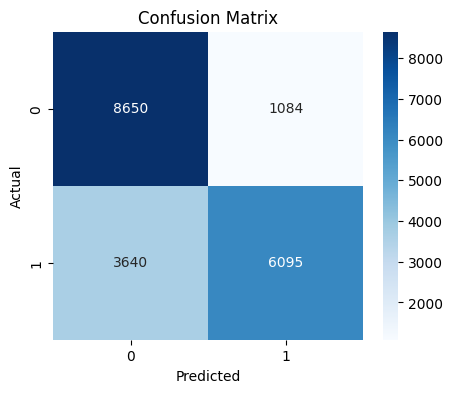


📋 Classification Report:
              precision    recall  f1-score   support

           0     0.7038    0.8886    0.7855      9734
           1     0.8490    0.6261    0.7207      9735

    accuracy                         0.7574     19469
   macro avg     0.7764    0.7574    0.7531     19469
weighted avg     0.7764    0.7574    0.7531     19469

Sensitivity (Recall): 0.6261
Specificity: 0.8886


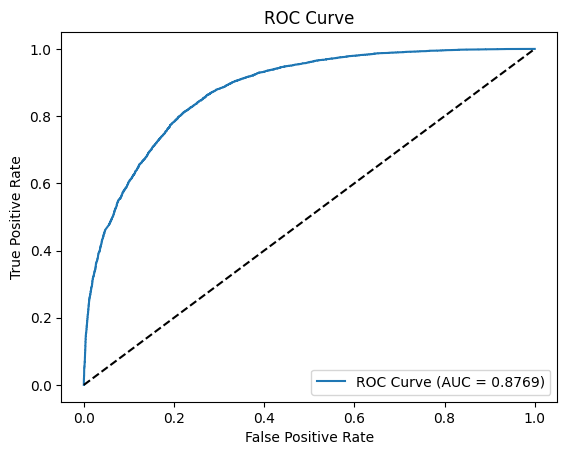

In [1]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, GlobalMaxPooling1D, Dropout, Input
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs from Kaggle input path
train_df = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_train.csv')
val_df   = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_val.csv')
test_df  = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_test.csv')

# ✅ Step 3: Validate Columns
expected_cols = ['Text', 'Features', 'isbully']
assert all(col in train_df.columns for col in expected_cols), "❌ Column mismatch!"

# 🧹 Step 4: Filter valid feature rows
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['Features'].apply(is_valid_feature)]
val_df   = val_df[val_df['Features'].apply(is_valid_feature)]
test_df  = test_df[test_df['Features'].apply(is_valid_feature)]

# 🔁 Step 5: Convert 'Features' to arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['Features']))
y_train = train_df['isbully'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['Features']))
y_val = val_df['isbully'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['Features']))
y_test = test_df['isbully'].astype(int).values

# 🔃 Step 6: Reshape for CNN
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_val   = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))
X_test  = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# 🧠 Step 7: Build CNN Model
model = Sequential([
    Input(shape=(X_train.shape[1], 1)),
    Conv1D(128, 5, activation='relu'),
    GlobalMaxPooling1D(),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 🚀 Step 8: Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    verbose=1
)

# 🧪 Step 9: Evaluate on test data
y_pred_prob = model.predict(X_test).ravel()
y_pred = (y_pred_prob > 0.5).astype(int)

# 📊 Step 10: Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", round(acc, 4))

# 📊 Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# 📊 Classification Report
print("\n📋 Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

# 📊 Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# 📈 ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


# **Random Forest# **

✅ Accuracy: 0.9784


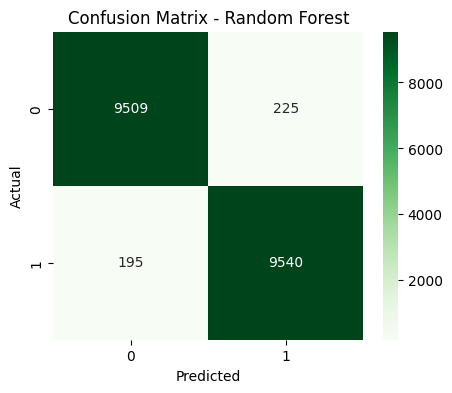


📋 Classification Report:

              precision    recall  f1-score   support

           0     0.9799    0.9769    0.9784      9734
           1     0.9770    0.9800    0.9785      9735

    accuracy                         0.9784     19469
   macro avg     0.9784    0.9784    0.9784     19469
weighted avg     0.9784    0.9784    0.9784     19469

Sensitivity (Recall): 0.9800
Specificity: 0.9769


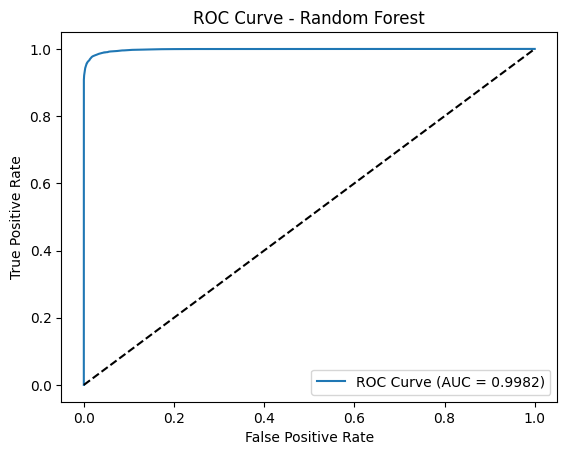

In [1]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs from Kaggle input directory
train_df = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_train.csv')
val_df   = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_val.csv')
test_df  = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_test.csv')

# ✅ Step 3: Confirm expected column names
expected_cols = ['Text', 'Features', 'isbully']
assert all(col in train_df.columns for col in expected_cols), "❌ Column mismatch!"

# 🧹 Step 4: Remove rows where 'Features' is not a valid list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['Features'].apply(is_valid_feature)]
val_df   = val_df[val_df['Features'].apply(is_valid_feature)]
test_df  = test_df[test_df['Features'].apply(is_valid_feature)]

# ✅ Step 5: Convert stringified feature vectors into NumPy arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['Features']))
y_train = train_df['isbully'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['Features']))
y_val = val_df['isbully'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['Features']))
y_test = test_df['isbully'].astype(int).values

# 🧠 Step 6: Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 📊 Step 7: Evaluate on test set
y_pred = rf_model.predict(X_test)
y_pred_prob = rf_model.predict_proba(X_test)[:, 1]

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", round(acc, 4))

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\n📋 Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend(loc='lower right')
plt.show()


# Decission Tree

✅ Accuracy: 0.9634


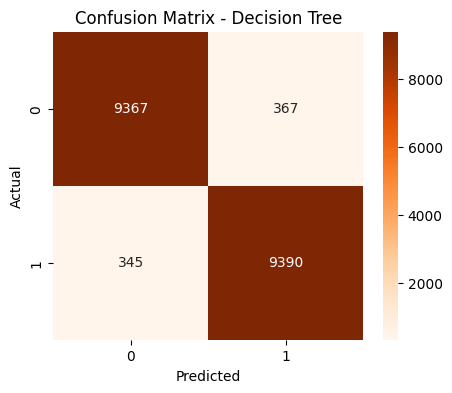


📋 Classification Report:

              precision    recall  f1-score   support

           0     0.9645    0.9623    0.9634      9734
           1     0.9624    0.9646    0.9635      9735

    accuracy                         0.9634     19469
   macro avg     0.9634    0.9634    0.9634     19469
weighted avg     0.9634    0.9634    0.9634     19469

Sensitivity (Recall): 0.9646
Specificity: 0.9623


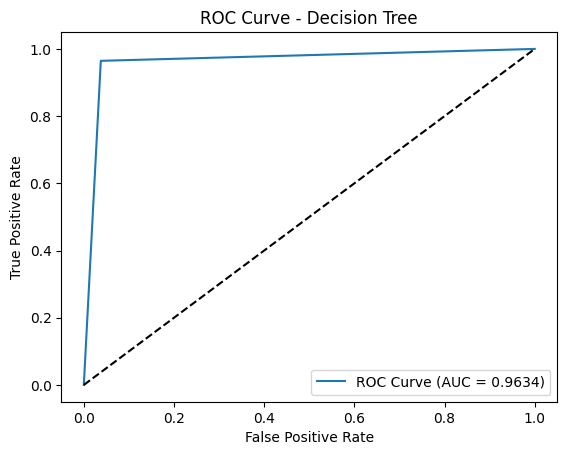

In [6]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs from Kaggle input directory
train_df = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_train.csv')
val_df   = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_val.csv')
test_df  = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_test.csv')

# ✅ Step 3: Confirm expected column names
expected_cols = ['Text', 'Features', 'isbully']
assert all(col in train_df.columns for col in expected_cols), "❌ Column mismatch!"

# 🧹 Step 4: Remove rows where 'Features' is not a valid list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['Features'].apply(is_valid_feature)]
val_df   = val_df[val_df['Features'].apply(is_valid_feature)]
test_df  = test_df[test_df['Features'].apply(is_valid_feature)]

# ✅ Step 5: Convert stringified feature vectors into NumPy arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['Features']))
y_train = train_df['isbully'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['Features']))
y_val = val_df['isbully'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['Features']))
y_test = test_df['isbully'].astype(int).values

# 🧠 Step 6: Train Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# 📊 Step 7: Evaluate on test set
y_pred = dt_model.predict(X_test)
y_pred_prob = dt_model.predict_proba(X_test)[:, 1]

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", round(acc, 4))

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\n📋 Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree')
plt.legend(loc='lower right')
plt.show()


# Naive Bias

✅ Accuracy: 0.7717


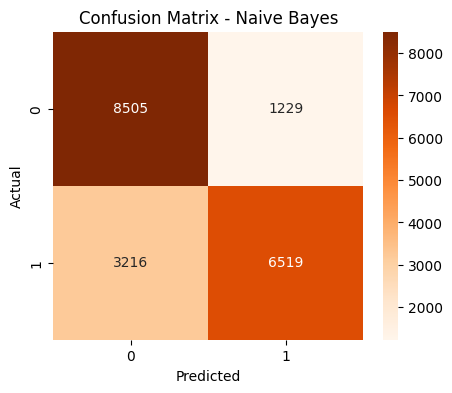


📋 Classification Report:

              precision    recall  f1-score   support

           0     0.7256    0.8737    0.7928      9734
           1     0.8414    0.6696    0.7458      9735

    accuracy                         0.7717     19469
   macro avg     0.7835    0.7717    0.7693     19469
weighted avg     0.7835    0.7717    0.7693     19469

Sensitivity (Recall): 0.6696
Specificity: 0.8737


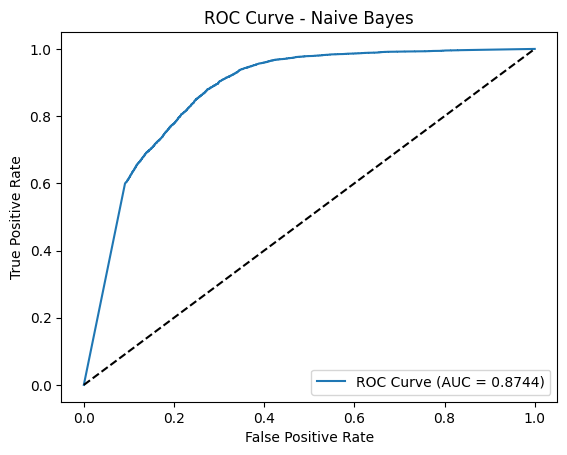

In [7]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs from balanced dataset path
train_df = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_train.csv')
val_df   = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_val.csv')
test_df  = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_test.csv')

# ✅ Step 3: Confirm expected column names
expected_cols = ['Text', 'Features', 'isbully']
assert all(col in train_df.columns for col in expected_cols), "❌ Column mismatch!"

# 🧹 Step 4: Remove rows where 'Features' is not a valid list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['Features'].apply(is_valid_feature)]
val_df   = val_df[val_df['Features'].apply(is_valid_feature)]
test_df  = test_df[test_df['Features'].apply(is_valid_feature)]

# ✅ Step 5: Convert stringified feature vectors into NumPy arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['Features']))
y_train = train_df['isbully'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['Features']))
y_val = val_df['isbully'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['Features']))
y_test = test_df['isbully'].astype(int).values

# 🧠 Step 6: Train Naive Bayes Classifier
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# 📊 Step 7: Evaluate the Model
y_pred = nb_model.predict(X_test)
y_pred_prob = nb_model.predict_proba(X_test)[:, 1]

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", round(acc, 4))

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\n📋 Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Naive Bayes')
plt.legend(loc='lower right')
plt.show()


# Logistic Regration

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


✅ Accuracy: 0.9781


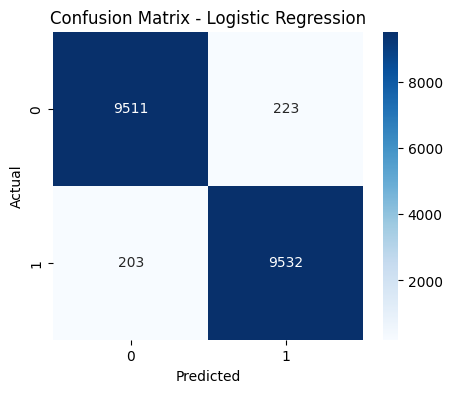


📋 Classification Report:

              precision    recall  f1-score   support

           0     0.9791    0.9771    0.9781      9734
           1     0.9771    0.9791    0.9781      9735

    accuracy                         0.9781     19469
   macro avg     0.9781    0.9781    0.9781     19469
weighted avg     0.9781    0.9781    0.9781     19469

Sensitivity (Recall): 0.9791
Specificity: 0.9771


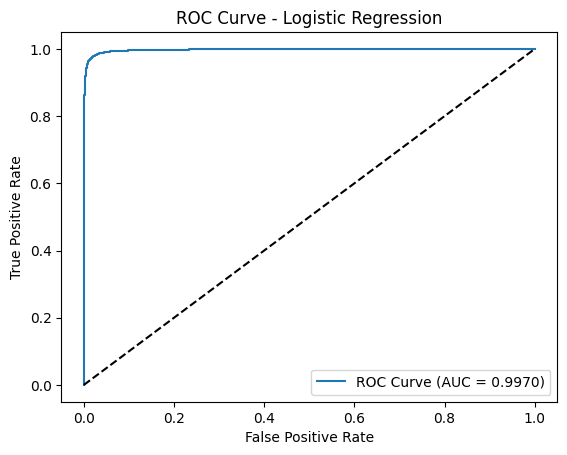

In [1]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs from Kaggle input directory
train_df = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_train.csv')
val_df   = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_val.csv')
test_df  = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_test.csv')

# ✅ Step 3: Confirm expected column names
expected_cols = ['Text', 'Features', 'isbully']
assert all(col in train_df.columns for col in expected_cols), "❌ Column mismatch!"

# 🧹 Step 4: Remove rows where 'Features' is not a valid list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['Features'].apply(is_valid_feature)]
val_df   = val_df[val_df['Features'].apply(is_valid_feature)]
test_df  = test_df[test_df['Features'].apply(is_valid_feature)]

# ✅ Step 5: Convert stringified feature vectors into NumPy arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['Features']))
y_train = train_df['isbully'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['Features']))
y_val = val_df['isbully'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['Features']))
y_test = test_df['isbully'].astype(int).values

# 🧠 Step 6: Train Logistic Regression Classifier
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

# 📊 Step 7: Evaluate the Model
y_pred = lr_model.predict(X_test)
y_pred_prob = lr_model.predict_proba(X_test)[:, 1]

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", round(acc, 4))

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\n📋 Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend(loc='lower right')
plt.show()


# LSTM

2025-07-27 09:42:53.910783: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753609374.105783      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753609374.163177      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
I0000 00:00:1753611091.633177      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1753611091.633906      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability:

Epoch 1/10


I0000 00:00:1753611098.125036     104 cuda_dnn.cc:529] Loaded cuDNN version 90300


2434/2434 ━━━━━━━━━━━━━━━━━━━━ 112s 44ms/step - accuracy: 0.5005 - loss: 0.6932 - val_accuracy: 0.5001 - val_loss: 0.6932
Epoch 2/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 107s 44ms/step - accuracy: 0.5015 - loss: 0.6932 - val_accuracy: 0.5001 - val_loss: 0.6931
Epoch 3/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 107s 44ms/step - accuracy: 0.4997 - loss: 0.6932 - val_accuracy: 0.4999 - val_loss: 0.6932
Epoch 4/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 107s 44ms/step - accuracy: 0.5002 - loss: 0.6932 - val_accuracy: 0.5001 - val_loss: 0.6932
Epoch 5/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 107s 44ms/step - accuracy: 0.5017 - loss: 0.6932 - val_accuracy: 0.5001 - val_loss: 0.6932
Epoch 6/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 107s 44ms/step - accuracy: 0.5001 - loss: 0.6932 - val_accuracy: 0.5001 - val_loss: 0.6932
Epoch 7/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 107s 44ms/step - accuracy: 0.4990 - loss: 0.6932 - val_accuracy: 0.5001 - val_loss: 0.6932
Epoch 8/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 107s 44ms/step - accuracy: 0.5009 - lo

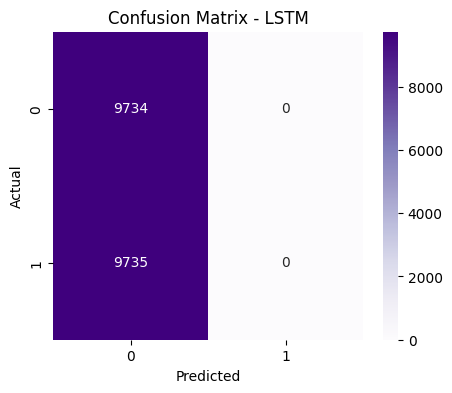


📋 Classification Report:

              precision    recall  f1-score   support

           0     0.5000    1.0000    0.6666      9734
           1     0.0000    0.0000    0.0000      9735

    accuracy                         0.5000     19469
   macro avg     0.2500    0.5000    0.3333     19469
weighted avg     0.2500    0.5000    0.3333     19469

Sensitivity (Recall): 0.0000
Specificity: 1.0000


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


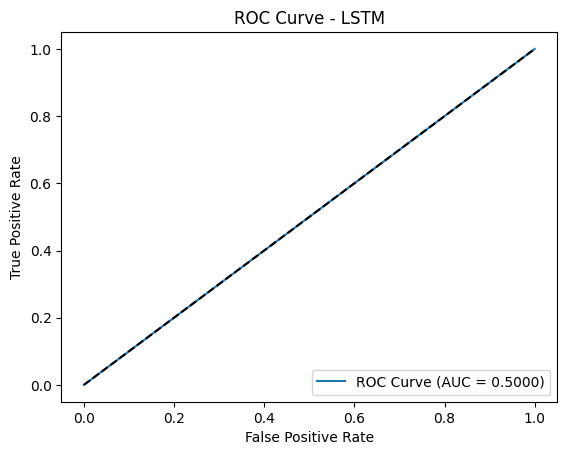

In [2]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs from Kaggle input directory
train_df = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_train.csv')
val_df   = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_val.csv')
test_df  = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_test.csv')

# ✅ Step 3: Validate column names
expected_cols = ['Text', 'Features', 'isbully']
assert all(col in train_df.columns for col in expected_cols), "❌ Column mismatch!"

# 🧹 Step 4: Remove rows where 'Features' is not a valid list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['Features'].apply(is_valid_feature)]
val_df   = val_df[val_df['Features'].apply(is_valid_feature)]
test_df  = test_df[test_df['Features'].apply(is_valid_feature)]

# ✅ Step 5: Convert stringified feature vectors into NumPy arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['Features']))
y_train = train_df['isbully'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['Features']))
y_val = val_df['isbully'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['Features']))
y_test = test_df['isbully'].astype(int).values

# 🔁 Step 6: Reshape for LSTM: (samples, timesteps, features)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_val   = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))
X_test  = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# 🧠 Step 7: Define the LSTM Model
model = Sequential([
    Input(shape=(X_train.shape[1], 1)),
    LSTM(64, return_sequences=False),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 🚀 Step 8: Train the Model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    verbose=1
)

# 📊 Step 9: Evaluate the Model
y_pred_prob = model.predict(X_test).ravel()
y_pred = (y_pred_prob > 0.5).astype(int)

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", round(acc, 4))

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')
plt.title("Confusion Matrix - LSTM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\n📋 Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - LSTM')
plt.legend(loc='lower right')
plt.show()


# RNN

2025-07-27 12:33:03.534222: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753619583.731848      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753619583.787885      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
I0000 00:00:1753621317.478549      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1753621317.479252      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability:

Epoch 1/10


I0000 00:00:1753621323.723907     105 service.cc:148] XLA service 0x7f4c14003480 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1753621323.724559     105 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1753621323.724576     105 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1753621324.029482     105 cuda_dnn.cc:529] Loaded cuDNN version 90300


   1/2434 ━━━━━━━━━━━━━━━━━━━━ 2:46:47 4s/step - accuracy: 0.3594 - loss: 0.6959

I0000 00:00:1753621325.306377     105 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2434/2434 ━━━━━━━━━━━━━━━━━━━━ 238s 96ms/step - accuracy: 0.5159 - loss: 0.6979 - val_accuracy: 0.5860 - val_loss: 0.6759
Epoch 2/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 231s 95ms/step - accuracy: 0.5735 - loss: 0.6830 - val_accuracy: 0.5820 - val_loss: 0.6793
Epoch 3/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 231s 95ms/step - accuracy: 0.5772 - loss: 0.6814 - val_accuracy: 0.5554 - val_loss: 0.6882
Epoch 4/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 231s 95ms/step - accuracy: 0.5334 - loss: 0.6901 - val_accuracy: 0.5025 - val_loss: 0.6931
Epoch 5/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 231s 95ms/step - accuracy: 0.4993 - loss: 0.6932 - val_accuracy: 0.5003 - val_loss: 0.6931
Epoch 6/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 231s 95ms/step - accuracy: 0.4944 - loss: 0.6931 - val_accuracy: 0.5003 - val_loss: 0.6930
Epoch 7/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 231s 95ms/step - accuracy: 0.5005 - loss: 0.6925 - val_accuracy: 0.5010 - val_loss: 0.6928
Epoch 8/10
2434/2434 ━━━━━━━━━━━━━━━━━━━━ 231s 95ms/step - accuracy: 0.5032 - lo

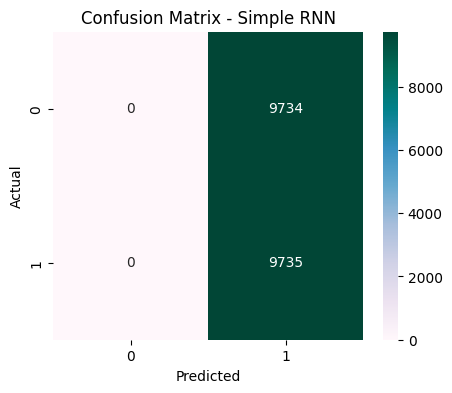


📋 Classification Report:

              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000      9734
           1     0.5000    1.0000    0.6667      9735

    accuracy                         0.5000     19469
   macro avg     0.2500    0.5000    0.3333     19469
weighted avg     0.2500    0.5000    0.3334     19469

Sensitivity (Recall): 1.0000
Specificity: 0.0000


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


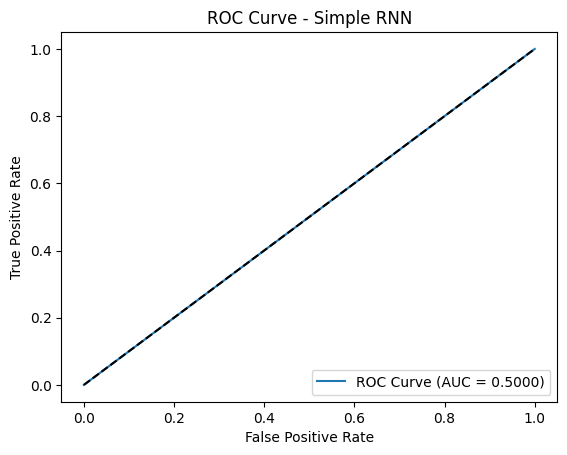

In [1]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout, Input
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs from Balanced Dataset
train_df = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_train.csv')
val_df   = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_val.csv')
test_df  = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_test.csv')

# ✅ Step 3: Confirm Columns
assert all(col in train_df.columns for col in ['Text', 'Features', 'isbully'])

# 🧹 Step 4: Filter Valid Feature Rows
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['Features'].apply(is_valid_feature)]
val_df   = val_df[val_df['Features'].apply(is_valid_feature)]
test_df  = test_df[test_df['Features'].apply(is_valid_feature)]

# 🔁 Step 5: Convert 'Features' Strings to NumPy Arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['Features']))
y_train = train_df['isbully'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['Features']))
y_val = val_df['isbully'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['Features']))
y_test = test_df['isbully'].astype(int).values

# 🔃 Step 6: Reshape for RNN input (samples, timesteps, features)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_val   = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))
X_test  = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# 🧠 Step 7: Build RNN Model
model = Sequential([
    Input(shape=(X_train.shape[1], 1)),
    SimpleRNN(64, return_sequences=False),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 🚀 Step 8: Train the Model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    verbose=1
)

# 📊 Step 9: Evaluate on Test Set
y_pred_prob = model.predict(X_test).ravel()
y_pred = (y_pred_prob > 0.5).astype(int)

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", round(acc, 4))

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='PuBuGn')
plt.title("Confusion Matrix - Simple RNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\n📋 Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Simple RNN')
plt.legend(loc='lower right')
plt.show()


# SVM Linear

/usr/local/lib/python3.11/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


✅ Accuracy: 0.9768


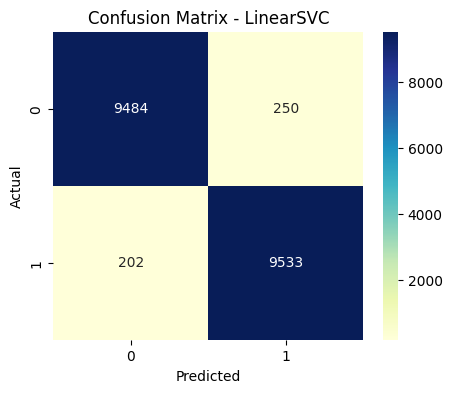


📋 Classification Report:

              precision    recall  f1-score   support

           0     0.9791    0.9743    0.9767      9734
           1     0.9744    0.9793    0.9768      9735

    accuracy                         0.9768     19469
   macro avg     0.9768    0.9768    0.9768     19469
weighted avg     0.9768    0.9768    0.9768     19469

Sensitivity (Recall): 0.9793
Specificity: 0.9743


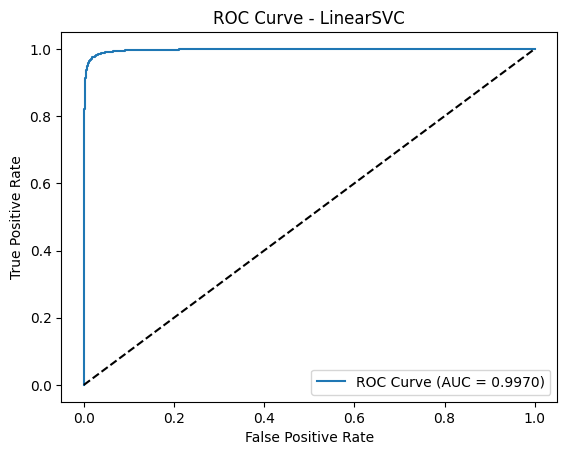

In [1]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load Balanced Dataset
train_df = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_train.csv')
val_df   = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_val.csv')
test_df  = pd.read_csv('/kaggle/input/cyber-bullying-balanced-dataset-with-emojis/final_test.csv')

# ✅ Step 3: Confirm Column Names
assert all(col in train_df.columns for col in ['Text', 'Features', 'isbully'])

# 🧹 Step 4: Filter Invalid Rows
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['Features'].apply(is_valid_feature)]
val_df   = val_df[val_df['Features'].apply(is_valid_feature)]
test_df  = test_df[test_df['Features'].apply(is_valid_feature)]

# 🔁 Step 5: Convert Features Column
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['Features']))
y_train = train_df['isbully'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['Features']))
y_val = val_df['isbully'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['Features']))
y_test = test_df['isbully'].astype(int).values

# 🧠 Step 6: Train LinearSVC (faster SVM)
svm_model = LinearSVC(max_iter=10000, random_state=42)
svm_model.fit(X_train, y_train)

# 📊 Step 7: Evaluate the Model
y_pred = svm_model.predict(X_test)
y_score = svm_model.decision_function(X_test)  # for ROC & AUC

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", round(acc, 4))

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu')
plt.title("Confusion Matrix - LinearSVC")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\n📋 Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = roc_auc_score(y_test, y_score)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - LinearSVC')
plt.legend(loc='lower right')
plt.show()
